# Bench E: summing stage

The M2M ladder, both NMOS and both PMOS regulated cascodes, the 40 uA copies and the clamp cells together (paper Fig. 11). The delta-I nodes `di_p`, `di_n` carry I_D1 − I1 and I_D2 − I2.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sarlib import specs as S
from sarlib.analysis import load_real, load_cols, parse_op_log, eng, log_cross, lin_cross, window_around, settle_time, Report

DATA = Path('simulation/summing_stage_w_clamps.sch')
s = S.summing
SP = s.SPECS
LSB = S.I_LSB
SWEEP_COLS = ['dip', 'din', 'vdac1', 'vdac2', 'vi1', 'vi2', 'vdip', 'vdin', 'vnet1', 'vnet3', 'vnet4', 'vnet6', 'idd']
rep = Report()

def inl_dnl(code, y):
    """Endpoint LSB, INL and DNL, and best-fit INL of y(code)."""
    lsb = (y[-1] - y[0]) / (code[-1] - code[0])
    p = np.polyfit(code, y, 1)
    return lsb, (y - y[0] - lsb * (code - code[0])) / lsb, np.diff(y) / (lsb * np.diff(code)) - 1, (y - np.polyval(p, code)) / p[0]

## Operating points

Mid code and both ends of the code range with the matching input current.

In [2]:
OP_LOGS = {'mid code': 'op_mid.log', 'code 0': 'op_lo.log', 'code 127': 'op_hi.log'}
PF, NF = 'msky130_fd_pr__pfet_01v8', 'msky130_fd_pr__nfet_01v8'
DEVICES = {lab: f'm.{d}.{t}' for lab, d, t in (
    ('XM1 V-to-I (p)', 'xm1', PF), ('XM2 p cascode (p)', 'xm2', PF), ('XM5 V-to-I (n)', 'xm5', PF), ('XM6 p cascode (n)', 'xm6', PF),
    ('XM8 sink (dac1)', 'xm8', NF), ('XM11 n cascode (p)', 'xm11', NF), ('XM14 sink (dac2)', 'xm14', NF), ('XM15 n cascode (n)', 'xm15', NF))}
OTA_N = [('M1', 'xm1', NF), ('M2', 'xm2', NF), ('M3', 'xm3', NF), ('M4', 'xm4', NF), ('M5', 'xm5', NF), ('M6', 'xm6', PF),
         ('M7', 'xm7', PF), ('M8', 'xm8', PF), ('M9', 'xm9', PF), ('M10', 'xm10', NF), ('M11', 'xm11', NF)]
OTA_P = [('M1', 'xm1', PF), ('M2', 'xm2', PF), ('M3', 'xm3', NF), ('M4', 'xm4', NF), ('M5', 'xm5', PF)]
for x, devs in (('x1', OTA_N), ('x2', OTA_N), ('x3', OTA_P), ('x4', OTA_P)):
    DEVICES.update({f'OTA {x} {lab}': f'm.{x}.{d}.{t}' for lab, d, t in devs})

nodes, margins = {}, []
for case, name in OP_LOGS.items():
    vals = parse_op_log(DATA / name)
    nodes[case] = {k: vals[k] for k in ('v(i1)', 'v(i2)', 'v(dac1)', 'v(dac2)', 'v(di_p)', 'v(di_n)', 'v(net1)', 'v(net3)', 'v(net4)', 'v(net6)')}
    nodes[case]['reg err i (mV)'] = 1e3 * max(abs(vals['v(i1)'] - S.VREF2), abs(vals['v(i2)'] - S.VREF2))
    nodes[case]['reg err dac (mV)'] = 1e3 * max(abs(vals['v(dac1)'] - S.VREF1), abs(vals['v(dac2)'] - S.VREF1))
    nodes[case]['idd'] = vals['idd']
    for dev, path in DEVICES.items():
        vds, vdsat = vals[f'@{path}[vds]'], vals[f'@{path}[vdsat]']
        margins.append(dict(case=case, device=dev, VDS=vds, VDSAT=vdsat, margin=abs(vds) - abs(vdsat)))
NODES, MARG = pd.DataFrame(nodes), pd.DataFrame(margins)
reg = max(NODES.loc['reg err i (mV)'].max(), NODES.loc['reg err dac (mV)'].max())
rep.check('min VDS - VDSAT, all devices and cases', eng(MARG.margin.min(), 'V'), f">= {1e3 * SP['op_margin_v']:.0f} mV",
          MARG.margin.min() >= SP['op_margin_v'])
rep.info('supply current', eng(NODES.loc['idd'].max(), 'A'))
rep.check('loops regulate (worst i1,i2 / dac1,dac2 error)', f'{reg:.1f} mV', f"<= {SP['reg_err_mv_max']:g} mV", reg <= SP['reg_err_mv_max'])
display(NODES.drop('idd').round(4))
MARG.sort_values('margin').head(10).round(3)

,mid code,code 0,code 127
v(i1),1.5501,1.5502,1.5501
v(i2),1.5501,1.5501,1.5502
v(dac1),0.2486,0.2484,0.2488
v(dac2),0.2486,0.2488,0.2484
v(di_p),0.9137,0.9143,0.9085
v(di_n),0.9149,0.9142,0.9203
v(net1),0.3587,0.3323,0.3925
v(net3),0.3587,0.3925,0.3322
v(net4),1.0296,1.0583,0.9951
v(net6),1.0295,0.9944,1.0578


,case,device,VDS,VDSAT,margin
40,code 0,XM1 V-to-I (p),0.249,0.203,0.046
82,code 127,XM5 V-to-I (n),0.249,0.203,0.046
2,mid code,XM5 V-to-I (n),0.249,0.203,0.046
0,mid code,XM1 V-to-I (p),0.249,0.203,0.046
42,code 0,XM5 V-to-I (n),0.249,0.203,0.046
80,code 127,XM1 V-to-I (p),0.249,0.203,0.046
108,code 127,OTA x2 M10,0.149,0.099,0.050
57,code 0,OTA x1 M10,0.149,0.099,0.051
103,code 127,OTA x2 M5,0.183,0.123,0.060
52,code 0,OTA x1 M5,0.183,0.123,0.060


## DAC in the loop

All 128 codes with I1 = I2 = 10 uA. Endpoint INL/DNL per side; the decision offset is where p − n crosses zero, relative to code I1 / I_LSB.

side p: LSB 156.16 nA (-0.06 %), INL 0.136 (best fit 0.133), DNL 0.206 LSB
side n: LSB 156.16 nA (-0.06 %), INL 0.135 (best fit 0.132), DNL 0.206 LSB
zero crossing at code 64.104 (offset +0.104 LSB); common-mode current 424 nA, 0.001 LSB p-p over the codes
dac1/dac2 move 0.42 / 0.42 mV, i1/i2 0.00 / 0.00 mV


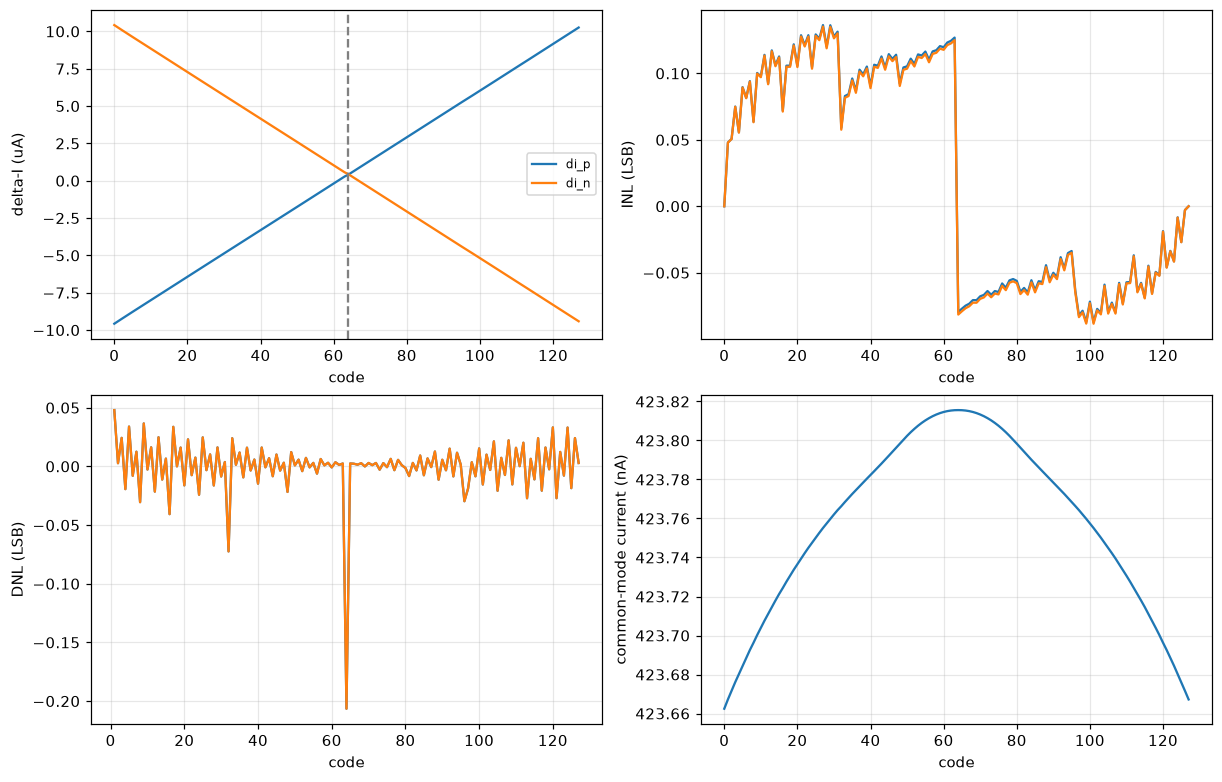

In [3]:
code, c = load_cols(DATA / 'code_sweep.csv', SWEEP_COLS)
sides = {}
for side, y in (('p', c['dip']), ('n', -c['din'])):
    lsb, inl, dnl, inl_bf = inl_dnl(code, y)
    sides[side] = dict(lsb=lsb, inl=inl, dnl=dnl, inl_max=np.abs(inl).max(), dnl_max=np.abs(dnl).max(), inl_bf_max=np.abs(inl_bf).max())
    print(f"side {side}: LSB {1e9 * lsb:.2f} nA ({100 * (lsb / LSB - 1):+.2f} %), INL {sides[side]['inl_max']:.3f} "
          f"(best fit {sides[side]['inl_bf_max']:.3f}), DNL {sides[side]['dnl_max']:.3f} LSB")
k0 = lin_cross(code, c['dip'] - c['din'])
offset = k0 - s.I1 / LSB
eps = 0.5 * (c['dip'] + c['din'])
print(f'zero crossing at code {k0:.3f} (offset {offset:+.3f} LSB); common-mode current {eng(eps.mean(), "A")}, '
      f'{(eps.max() - eps.min()) / LSB:.3f} LSB p-p over the codes')
print(f"dac1/dac2 move {1e3 * np.ptp(c['vdac1']):.2f} / {1e3 * np.ptp(c['vdac2']):.2f} mV, i1/i2 {1e3 * np.ptp(c['vi1']):.2f} / {1e3 * np.ptp(c['vi2']):.2f} mV")
inl = max(v['inl_max'] for v in sides.values())
dnl = max(v['dnl_max'] for v in sides.values())
mono = all(v['dnl'].min() > -1 for v in sides.values())
rep.check('INL, endpoint, worst side', f'{inl:.3f} LSB', f"<= {SP['inl_lsb_max']} LSB", inl <= SP['inl_lsb_max'])
rep.check('DNL, worst side', f'{dnl:.3f} LSB', f"<= {SP['dnl_lsb_max']} LSB", dnl <= SP['dnl_lsb_max'])
rep.check('monotonic', 'yes' if mono else 'no', 'yes', mono)
rep.check('decision offset', f'{offset:+.3f} LSB', f"|.| <= {SP['offset_lsb_max']} LSB", abs(offset) <= SP['offset_lsb_max'])
rep.info('LSB size error', f"{max(abs(100 * (v['lsb'] / LSB - 1)) for v in sides.values()):.3f} %")

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax[0, 0].plot(code, 1e6 * c['dip'], label='di_p'); ax[0, 0].plot(code, 1e6 * c['din'], label='di_n')
ax[0, 0].axvline(s.I1 / LSB, c='gray', ls='--'); ax[0, 0].set(xlabel='code', ylabel='delta-I (uA)'); ax[0, 0].legend(fontsize=8)
for side, col in (('p', 'C0'), ('n', 'C1')):
    ax[0, 1].plot(code, sides[side]['inl'], color=col, label=side)
    ax[1, 0].plot(code[1:], sides[side]['dnl'], color=col, label=side)
ax[0, 1].set(xlabel='code', ylabel='INL (LSB)'); ax[1, 0].set(xlabel='code', ylabel='DNL (LSB)')
ax[1, 1].plot(code, 1e9 * eps); ax[1, 1].set(xlabel='code', ylabel='common-mode current (nA)')
plt.show()

## Input current sweep

Mid code, I1 from 0 to 20 uA with I2 = 20 uA − I1: delta-I should be a line of slope ∓1.

side p: slope -0.99992, worst deviation 0.001 LSB
side n: slope +0.99992, worst deviation 0.001 LSB
vnet1: 0.331 to 0.393 V
vnet3: 0.331 to 0.393 V
vnet4: 1.028 to 1.031 V
vnet6: 1.028 to 1.031 V


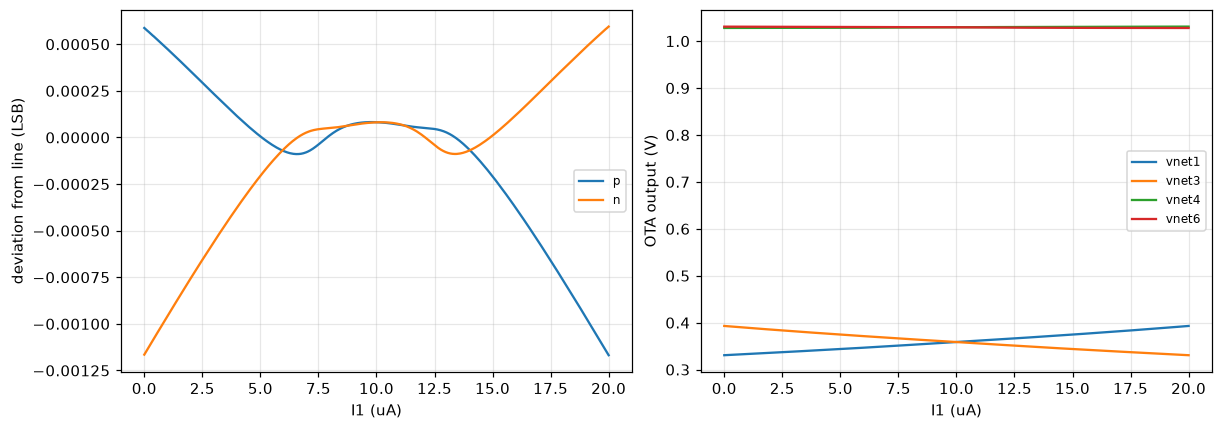

In [4]:
x, c = load_cols(DATA / 'in_sweep.csv', SWEEP_COLS)
mid = (x >= x.min() + 0.25 * np.ptp(x)) & (x <= x.min() + 0.75 * np.ptp(x))
lin = {}
for side, y, ideal in (('p', c['dip'], -1.0), ('n', c['din'], 1.0)):
    pf = np.polyfit(x[mid], y[mid], 1)
    resid = (y - np.polyval(pf, x)) / LSB
    w = window_around(x, np.abs(resid) < SP['lin_tol_lsb'], 1e6 * s.I1)
    lin[side] = dict(slope=pf[0] / 1e-6, resid=resid, covers=bool(w and w[0] <= x.min() + 0.05 and w[1] >= x.max() - 0.05))
    print(f"side {side}: slope {lin[side]['slope']:+.5f}, worst deviation {np.abs(resid).max():.3f} LSB")
for n in ('vnet1', 'vnet3', 'vnet4', 'vnet6'):
    print(f'{n}: {c[n].min():.3f} to {c[n].max():.3f} V')
ok = lin['p']['covers'] and lin['n']['covers']
rep.check('delta-I vs I1 straight over 0-20 uA', 'yes' if ok else 'no', 'yes', ok)
rep.check('slope of delta-I vs I1 (p / n)', f"{lin['p']['slope']:+.4f} / {lin['n']['slope']:+.4f}", '-1 / +1 within 1 %',
          abs(lin['p']['slope'] + 1) < 0.01 and abs(lin['n']['slope'] - 1) < 0.01)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(x, lin['p']['resid'], label='p'); ax[0].plot(x, lin['n']['resid'], label='n')
ax[0].set(xlabel='I1 (uA)', ylabel='deviation from line (LSB)'); ax[0].legend(fontsize=8)
for n in ('vnet1', 'vnet3', 'vnet4', 'vnet6'):
    ax[1].plot(x, c[n], label=n)
ax[1].set(xlabel='I1 (uA)', ylabel='OTA output (V)'); ax[1].legend(fontsize=8)
plt.show()

## Clamp voltage transfer

The differential node voltage over all codes with the clamp cells in place.

differential step per code 7.581 mV (2 R_tr I_LSB = 10.312 mV); voltage-transfer INL 13.30 LSB
common mode 0.949 V (+48.6 mV from V_MID), 47.1 mV p-p; nodes 0.712 to 1.195 V


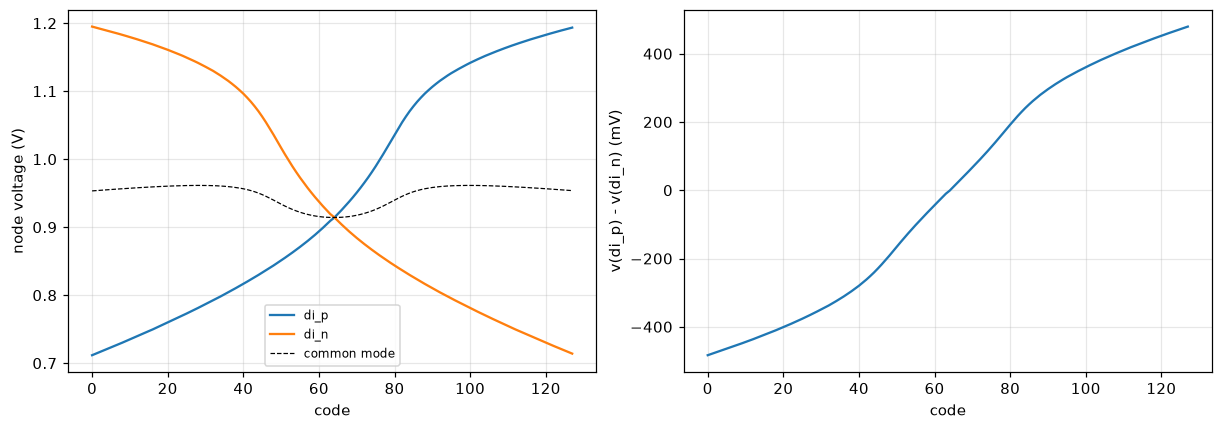

In [5]:
code, c = load_cols(DATA / 'code_sweep_clamp.csv', SWEEP_COLS)
vd, cm = c['vdip'] - c['vdin'], 0.5 * (c['vdip'] + c['vdin'])
VLSB, inl_v, _, _ = inl_dnl(code, vd)
print(f'differential step per code {1e3 * VLSB:.3f} mV (2 R_tr I_LSB = {2e3 * s.R_TR * LSB:.3f} mV); voltage-transfer INL {np.abs(inl_v).max():.2f} LSB')
print(f'common mode {cm.mean():.3f} V ({1e3 * (cm.mean() - S.VMID):+.1f} mV from V_MID), {1e3 * np.ptp(cm):.1f} mV p-p; '
      f"nodes {min(c['vdip'].min(), c['vdin'].min()):.3f} to {max(c['vdip'].max(), c['vdin'].max()):.3f} V")
rep.info('differential V per LSB', f'{1e3 * VLSB:.2f} mV', f'2 R_tr I_LSB = {2e3 * s.R_TR * LSB:.2f} mV')
rep.info('common-mode shift of the delta-I nodes', f'{1e3 * (cm.mean() - S.VMID):+.1f} mV')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(code, c['vdip'], label='di_p'); ax[0].plot(code, c['vdin'], label='di_n'); ax[0].plot(code, cm, 'k--', lw=0.8, label='common mode')
ax[0].set(xlabel='code', ylabel='node voltage (V)'); ax[0].legend(fontsize=8)
ax[1].plot(code, 1e3 * vd); ax[1].set(xlabel='code', ylabel='v(di_p) - v(di_n) (mV)')
plt.show()

## Small signal

transresistance 71.5 kohm (2 R_tr = 66 kohm), f-3dB 15 MHz, peaking 0.00 dB


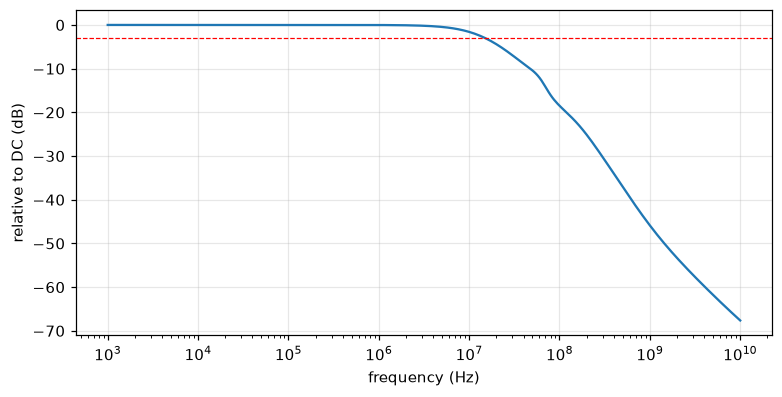

In [6]:
f, (db, ph) = load_real(DATA / 'ac.csv')
r0 = 10 ** (db[0] / 20) / 1e-6
f3 = log_cross(f, db, db[0] - 3.0)
peak = db.max() - db[0]
print(f'transresistance {eng(r0, "ohm")} (2 R_tr = {eng(2 * s.R_TR, "ohm")}), f-3dB {eng(f3, "Hz")}, peaking {peak:.2f} dB')
rep.check('DC transresistance vs 2 R_tr', f'{100 * (r0 / (2 * s.R_TR) - 1):+.1f} %', '|.| <= 5 %', abs(r0 / (2 * s.R_TR) - 1) <= 0.05)
rep.info('-3 dB frequency', eng(f3, 'Hz'))
rep.check('peaking', f'{peak:.2f} dB', f"<= {SP['peaking_db_max']:g} dB", peak <= SP['peaking_db_max'])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(f, db - db[0]); ax.axhline(-3, c='r', ls='--', lw=0.8); ax.set(xlabel='frequency (Hz)', ylabel='relative to DC (dB)')
plt.show()

## Code-step transient

Settling of the differential node voltage to 0.5 LSB after each code step (63 → 64 is the major carry).

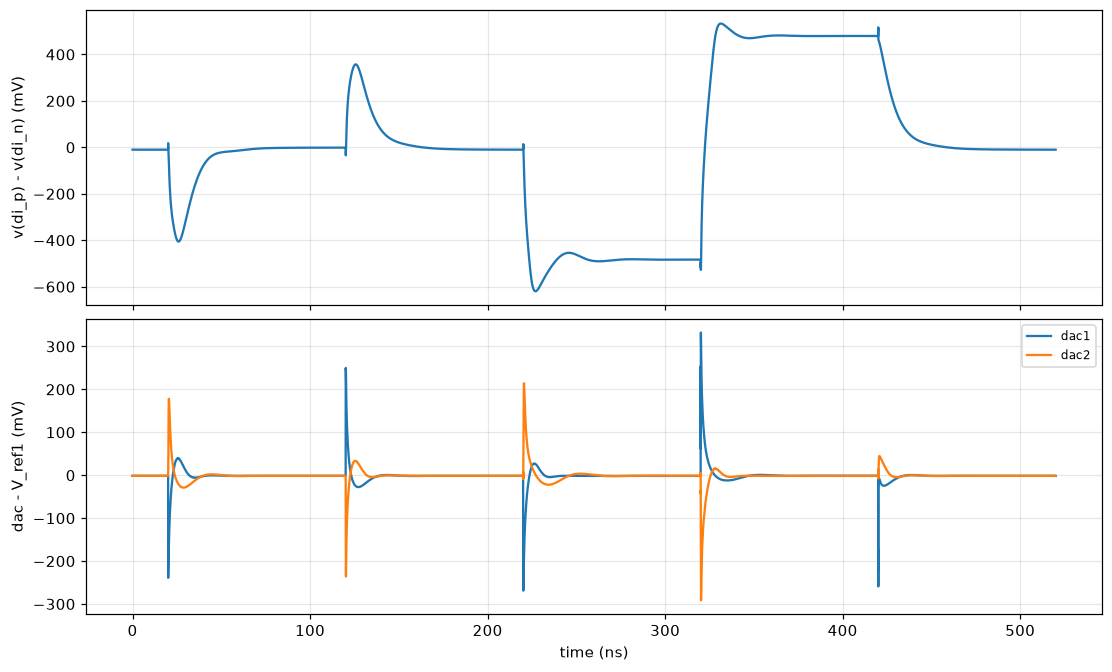

,step_mV,expected_mV,settle_ns,overshoot_mV,wrong_way_mV,dac_dev_mV,i_dev_mV
step,,,,,,,
63 -> 64,8.81,7.58,51.38,19.05,395.68,238.95,2.49
64 -> 63,-8.72,-7.58,53.11,24.33,358.53,249.85,2.13
63 -> 0,-473.32,-477.62,49.43,136.34,23.24,268.91,4.34
0 -> 127,962.76,962.83,34.07,53.51,44.31,332.34,3.85
127 -> 63,-489.47,-485.20,48.67,0.02,36.93,258.93,1.00


In [7]:
t, c = load_cols(DATA / 'tran.csv', ['vdip', 'vdin', 'vdac1', 'vdac2', 'vi1', 'vi2', 'vnet1', 'vnet3'])
vd = c['vdip'] - c['vdin']
edges = [0.0] + [e[0] for e in s.TRAN_EVENTS] + [t[-1]]
rows = []
for k, (te, c0, c1) in enumerate(s.TRAN_EVENTS):
    t_prev, t_next = edges[k], edges[k + 2]
    v0 = vd[(t > te - 0.1 * (te - t_prev)) & (t < te)].mean()
    v1 = vd[(t > t_next - 0.1 * (t_next - te)) & (t <= t_next)].mean()
    seg = (t >= te) & (t <= t_next)
    sgn = 1.0 if v1 >= v0 else -1.0
    rows.append(dict(step=f'{c0} -> {c1}', step_mV=1e3 * (v1 - v0), expected_mV=1e3 * (c1 - c0) * VLSB,
                     settle_ns=1e9 * settle_time(t[seg], vd[seg], v1, s.SETTLE_BAND_LSB * abs(VLSB), te),
                     overshoot_mV=1e3 * max(0.0, np.max(sgn * (vd[seg] - v1))), wrong_way_mV=1e3 * max(0.0, np.max(sgn * (v0 - vd[seg]))),
                     dac_dev_mV=1e3 * max(np.abs(c['vdac1'][seg] - S.VREF1).max(), np.abs(c['vdac2'][seg] - S.VREF1).max()),
                     i_dev_mV=1e3 * max(np.abs(c['vi1'][seg] - S.VREF2).max(), np.abs(c['vi2'][seg] - S.VREF2).max())))
TRAN = pd.DataFrame(rows).set_index('step')
rep.info('worst settling time', f"{TRAN.settle_ns.max():.1f} ns")
rep.info('worst dac1/dac2 disturbance', f"{TRAN.dac_dev_mV.max():.1f} mV")
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(1e9 * t, 1e3 * vd); ax[0].set_ylabel('v(di_p) - v(di_n) (mV)')
ax[1].plot(1e9 * t, 1e3 * (c['vdac1'] - S.VREF1), label='dac1'); ax[1].plot(1e9 * t, 1e3 * (c['vdac2'] - S.VREF1), label='dac2')
ax[1].set(xlabel='time (ns)', ylabel='dac - V_ref1 (mV)'); ax[1].legend(fontsize=8)
plt.show()
TRAN.round(2)

## Summary

In [8]:
rep.table()

,check,value,spec,result
0,"min VDS - VDSAT, all devices and cases",46.4 mV,>= 50 mV,FAIL
1,supply current,352 uA,,INFO
2,"loops regulate (worst i1,i2 / dac1,dac2 error)",1.6 mV,<= 20 mV,PASS
3,"INL, endpoint, worst side",0.136 LSB,<= 0.5 LSB,PASS
4,"DNL, worst side",0.206 LSB,<= 0.5 LSB,PASS
5,monotonic,yes,yes,PASS
6,decision offset,+0.104 LSB,|.| <= 0.5 LSB,PASS
7,LSB size error,0.058 %,,INFO
8,delta-I vs I1 straight over 0-20 uA,yes,yes,PASS
9,slope of delta-I vs I1 (p / n),-0.9999 / +0.9999,-1 / +1 within 1 %,PASS
